# Image classification — look at your data first

Most failed projects fail here, not in the model. Before training anything, answer:
1. **What classes exist, and how many images in each?** (imbalance changes everything downstream)
2. **What do the images actually look like?** (resolution, colour, background, artifacts)
3. **Could a human tell the classes apart?** (if not, check the labels before blaming the model)

In [1]:
# Run this cell first.
# On Colab it clones the kit and installs what's missing; locally it just finds the repo root.
import os, sys, subprocess
from pathlib import Path

if "google.colab" in sys.modules and not Path("cvkit").exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/standungan/computer-vision-starter-kit"], check=True)
    os.chdir("computer-vision-starter-kit")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyyaml", "scikit-learn", "gradio"], check=True)
while not Path("cvkit").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)          # notebooks live 3 folders below the repo root
sys.path.insert(0, os.getcwd())
print("working in", Path.cwd().name)

working in computer-vision-starter-kit


In [2]:
%config InlineBackend.figure_format = "jpeg"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 90}}   # keeps saved notebooks small

from PIL import Image

from cvkit.config import load_config
from cvkit.synthetic import make_demo_data
from cvkit.utils import seed_everything

# quick.yaml = small synthetic demo, runs on a laptop CPU in minutes.
# Swap in default.yaml (bigger, pretrained) or your own config + data when you're ready.
CONFIG = "tasks/classification/configs/quick.yaml"
cfg = load_config(CONFIG)
seed_everything(cfg["seed"])

if not Path(cfg["data"]["root"]).exists():          # first run: create the demo dataset
    make_demo_data("classification", cfg)
print("task:", "classification", "| data:", cfg["data"]["root"], "| outputs:", cfg["output"]["dir"])

task: classification | data: data/demo/classification | outputs: outputs/classification_quick


## How the data is organised
One folder per class — the folder name is the label (`root/<class>/*.jpg`). Splits are made per class (*stratified*), so every split keeps the class balance, and a fixed `seed` makes them identical on every run.

## Class inventory

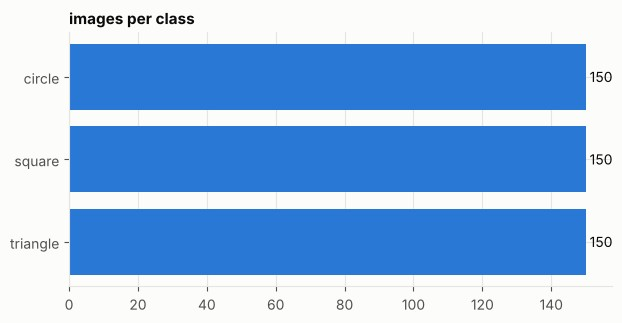

3 classes, 450 images


In [3]:
import matplotlib.pyplot as plt
from cvkit.viz import BLUE
from tasks.classification.data import build_datasets

ds = build_datasets(cfg)
classes = ds["classes"]
counts = [ds["class_counts"][i] for i in range(len(classes))]

fig, ax = plt.subplots(figsize=(7, 0.6 * len(classes) + 1.5))
ax.barh(classes, counts, color=BLUE)
ax.invert_yaxis()
for i, c in enumerate(counts):
    ax.text(c, i, f" {c}", va="center")
ax.set_title("images per class")
plt.show()
print(f"{len(classes)} classes, {sum(counts)} images")
if max(counts) > 2 * min(counts):
    print("WARNING: more than 2x class imbalance - look at per-class metrics, consider a weighted loss or oversampling")

## Look at the images
One row per class, straight off disk with no transforms. This is the single highest-value cell in the notebook.

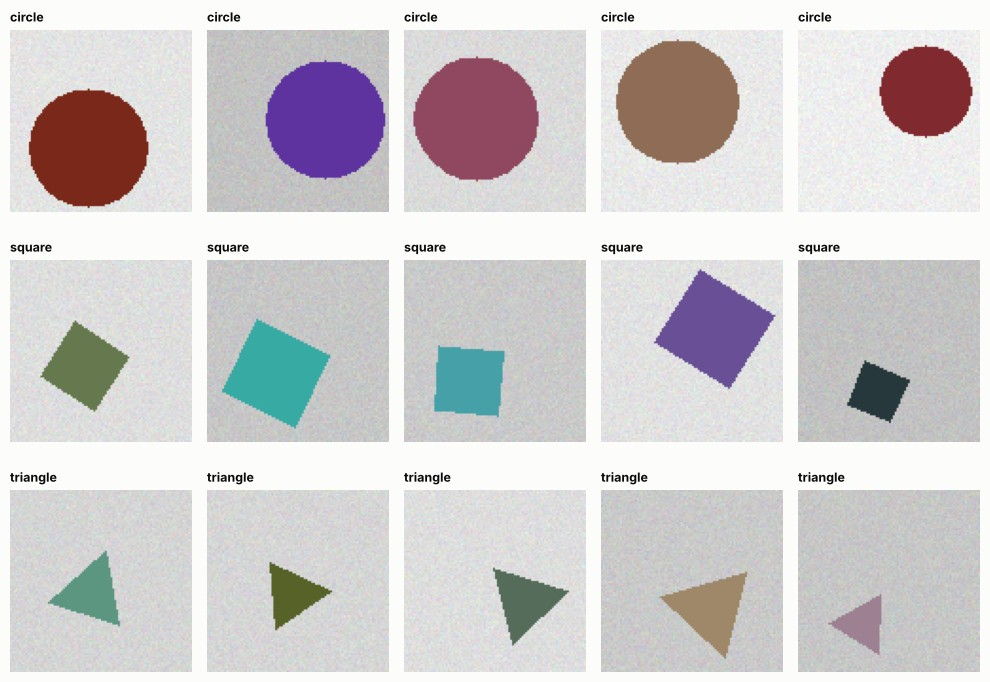

In [4]:
import random
from PIL import Image
from cvkit.viz import image_grid

rng = random.Random(cfg["seed"])
per_class, images, titles = 5, [], []
for ci, name in enumerate(classes):
    paths = [p for p, t in ds["samples"] if t == ci]
    for p in rng.sample(paths, min(per_class, len(paths))):
        images.append(Image.open(p)); titles.append(name)
_ = image_grid(images, titles, cols=per_class, cell=2.0)

## Image geometry
Mixed sizes are fine (everything is resized to `image_size`), but you want to *know* before choosing it.

In [5]:
from collections import Counter

sizes = Counter()
for path, _ in ds["samples"][:300]:
    with Image.open(path) as im:
        sizes[im.size + (im.mode,)] += 1
for (w, h, mode), n in sizes.most_common(5):
    print(f"{w}x{h} {mode}: {n} images")
print(f"\nconfig image_size: {cfg['data']['image_size']} (every image is resized to this square)")

96x96 RGB: 300 images

config image_size: 96 (every image is resized to this square)


## Augmentation
Same image, eight draws of the *training* transform, next to the deterministic *evaluation* transform. If an augmented image could plausibly change class, the augmentation is too aggressive.

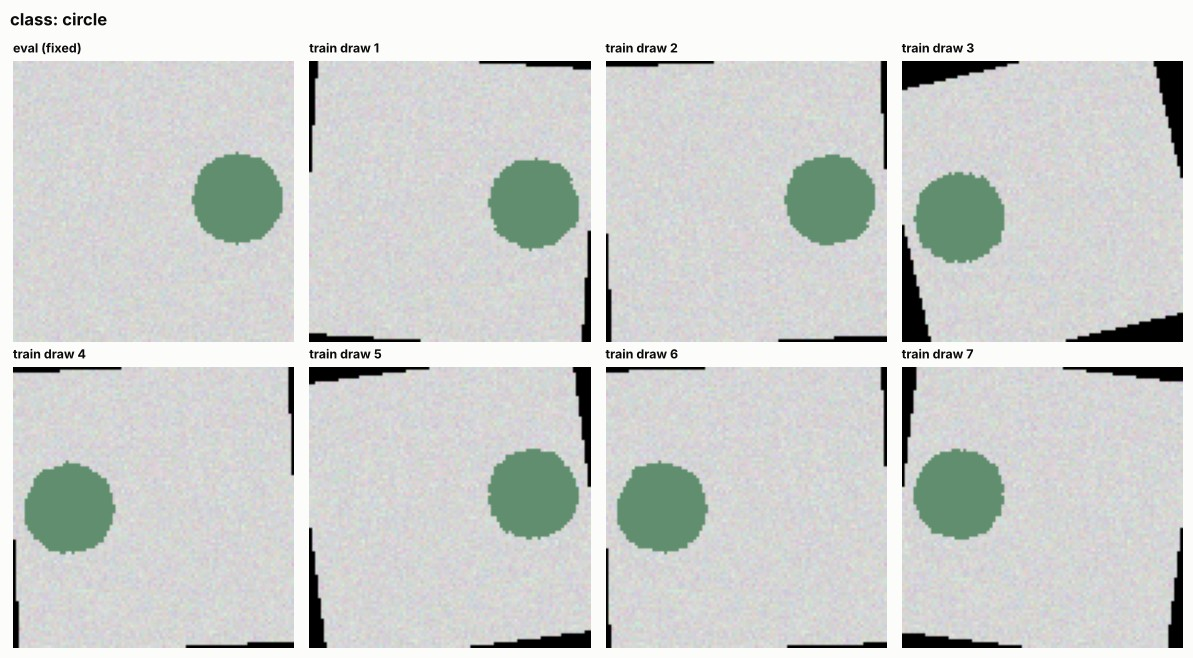

In [6]:
from cvkit.data import denormalize, image_transforms
from cvkit.viz import image_grid
from tasks.classification.data import build_datasets

ds = build_datasets(cfg)
size, aug = cfg["data"]["image_size"], cfg["data"]["augment"]
train_tf, eval_tf = image_transforms(size, aug, True), image_transforms(size, aug, False)
path, target = ds["samples"][0]
img = Image.open(path).convert("RGB")
shown = [denormalize(eval_tf(img))] + [denormalize(train_tf(img)) for _ in range(7)]
_ = image_grid(shown, ["eval (fixed)"] + [f"train draw {i}" for i in range(1, 8)], cols=4,
               suptitle=f"class: {ds['classes'][target]}")

## What the model will actually receive
One batch from the training loader, exactly as `train()` gets it:

images: (16, 3, 96, 96) torch.float32 | labels: (16,) torch.int64


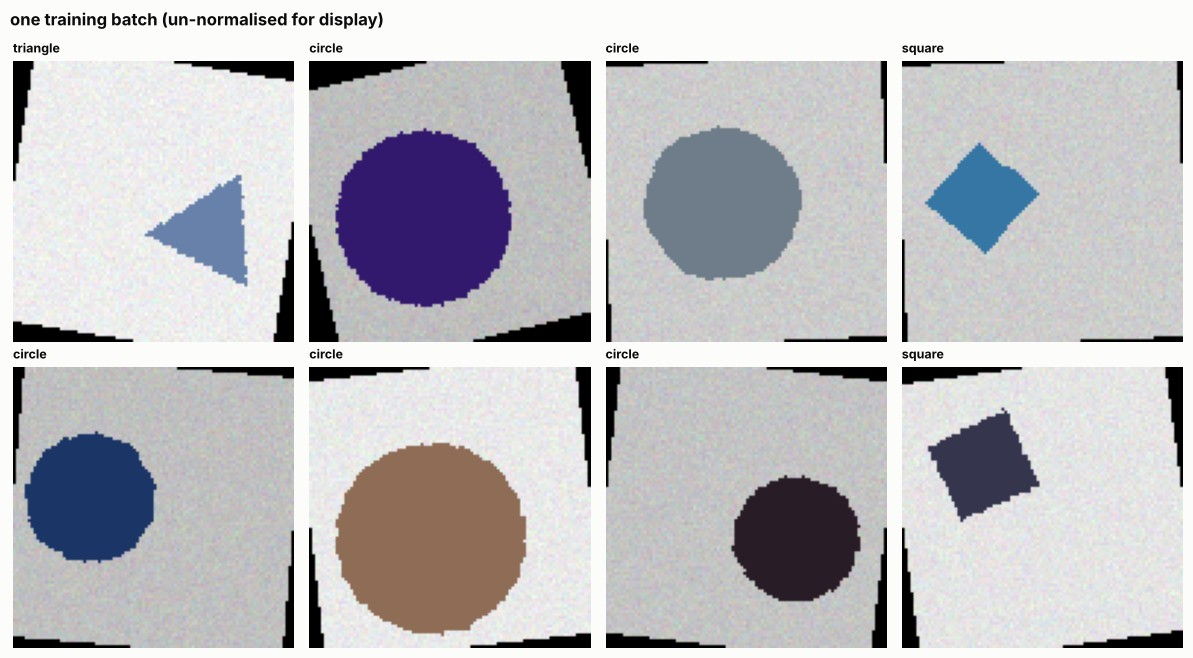

In [7]:
from cvkit.data import denormalize
from cvkit.viz import image_grid
from tasks.classification.data import build_loaders

loaders = build_loaders(cfg)
images, labels = next(iter(loaders["train"]))
print("images:", tuple(images.shape), images.dtype, "| labels:", tuple(labels.shape), labels.dtype)
_ = image_grid([denormalize(i) for i in images[:8]], [loaders["classes"][l] for l in labels[:8]], cols=4,
               suptitle="one training batch (un-normalised for display)")

## Before moving on
- [ ] Every class folder has images, and the names make sense
- [ ] No class is drowning the others (or you have a plan)
- [ ] You looked at real images and the labels match what you see
- [ ] `image_size` suits the native resolution

Next: **[02_train_and_evaluate](02_train_and_evaluate.ipynb)**.